# Fraud signal audit: card_type and channel

Doubt to test: these two categoricals may carry (almost) no fraud signal. Same pre-registered machinery as the time-feature analysis:

1. level tables `P(is_fraud | level)` with 95% intervals, per region (all / alarm / no_alarm);
2. MI vs a 10-shuffle null with Cramer's V, per column and for the joint combination;
3. dependence between the two columns themselves (do they overlap or just multiply the space?);
4. the fold-wise permutation test on the baseline: AUC drop when the column is shuffled, with `merchant_risk_score` as the reference scale.


In [1]:
import importlib
import json
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
    get_training_config_path,
    get_training_oof_path,
)
from scipy.stats import chi2_contingency
from sklearn.metrics import mutual_info_score, roc_auc_score
from tqdm.auto import tqdm
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS, NUMERIC_COLUMNS, prepare_features

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "fraud_by_card_type_channel"
EXP_NAME = "hgb_baseline"
MERCHANT_COL = "merchant_category"
AUTH_COL = "auth_method"
N_PERM = 10
MI_MARGIN = 1.1
V_FLOOR = 0.02
EFFECT_STRONG = 0.05
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
frame = train_df.copy()
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
REGIONS = {
    "all": np.ones(len(frame), dtype=bool),
    "alarm": has_alarm.to_numpy(dtype=bool),
    "no_alarm": (~has_alarm.to_numpy(dtype=bool)),
}
for _name, _mask in REGIONS.items():
    _part = frame.loc[_mask]
    print(_name, len(_part), int(_part[TARGET_COLUMN].sum()))


def entropy(labels) -> float:
    return float(mutual_info_score(labels, labels))


def chi2_independence(left, right):
    table = pd.crosstab(left, right)
    chi2, p_value, dof, _ = chi2_contingency(table)
    n = float(table.to_numpy().sum())
    k = min(table.shape) - 1
    if k == 0:
        return 0.0, 1.0, 0, 0.0
    cramers_v = float(np.sqrt(chi2 / (n * k)))
    return float(chi2), float(p_value), int(dof), cramers_v


def mi_vs_null(left, right, n_perm=N_PERM, seed=0):
    observed = float(mutual_info_score(left, right))
    rng = np.random.default_rng(seed)
    right_arr = np.asarray(right)
    null = np.empty(n_perm, dtype=np.float64)
    for i in range(n_perm):
        null[i] = float(mutual_info_score(left, rng.permutation(right_arr)))
    return observed, null


def interaction_verdict(observed, null_max, effect, floor):
    beats_null = observed > MI_MARGIN * float(null_max)
    if not beats_null:
        return "independent"
    if effect < floor:
        return "detectable_not_exploitable"
    if effect < EFFECT_STRONG:
        return "weak"
    return "strong"


P(is_fraud | card_type) in all (base rate 0.0167)
                 n  n_fraud    rate    lift  rate_lo  rate_hi
card_type                                                    
Amex         45797    871.0  0.0190  1.1389   0.0178   0.0203
Discover     17235    251.0  0.0146  0.8721   0.0128   0.0164
Mastercard  254857   4084.0  0.0160  0.9596   0.0155   0.0165
RuPay        37070    623.0  0.0168  1.0064   0.0155   0.0181
Visa        345001   5860.0  0.0170  1.0171   0.0166   0.0174
--------------------------------------------------
P(is_fraud | card_type) in alarm (base rate 0.0897)
                n  n_fraud    rate    lift  rate_lo  rate_hi
card_type                                                   
Amex         3493    362.0  0.1036  1.1549   0.0935   0.1137
Discover     1342    117.0  0.0872  0.9715   0.0721   0.1023
Mastercard  19391   1627.0  0.0839  0.9350   0.0800   0.0878
RuPay        2748    269.0  0.0979  1.0909   0.0868   0.1090
Visa        26048   2383.0  0.0915  1.0195   0.

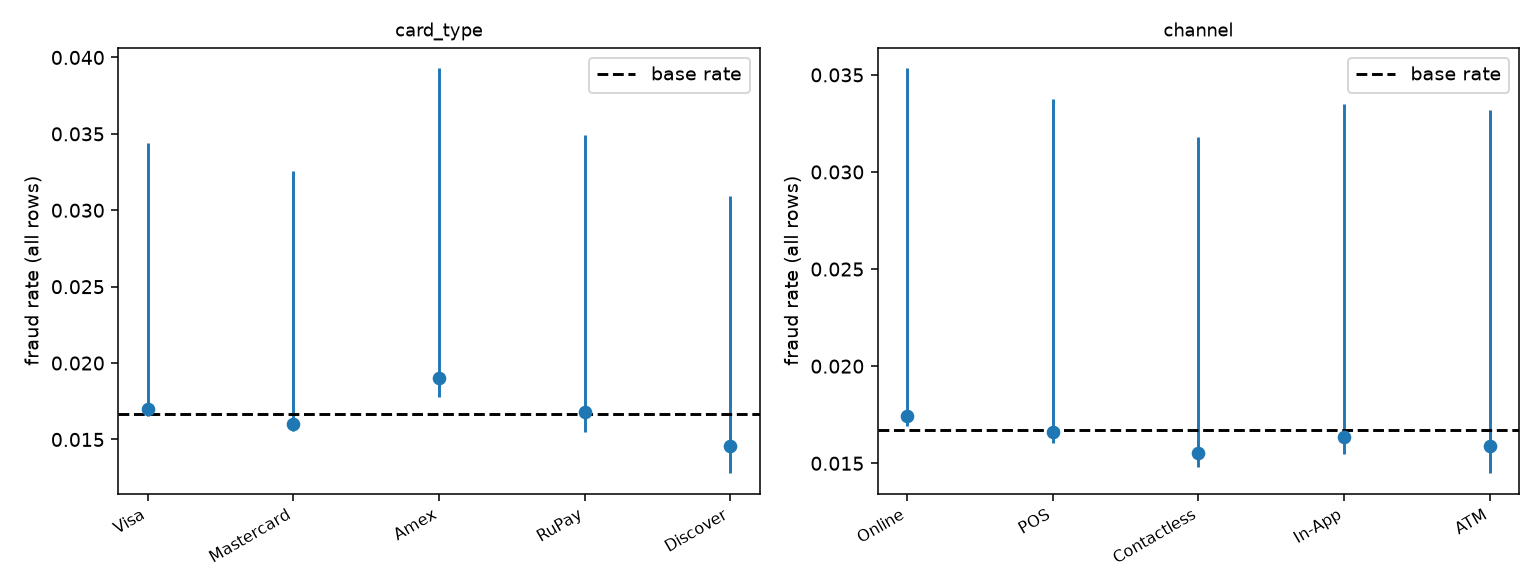

In [2]:
AUDIT_COLUMNS = ("card_type", "channel")

level_parts: dict[str, pd.DataFrame] = {}
for col in AUDIT_COLUMNS:
    for region_name, mask in REGIONS.items():
        part = frame.loc[mask]
        base_rate = float(part[TARGET_COLUMN].mean())
        grouped = part.groupby(col, observed=True)[TARGET_COLUMN].agg(["size", "sum"])
        grouped.columns = ["n", "n_fraud"]
        grouped["rate"] = grouped["n_fraud"] / grouped["n"]
        grouped["lift"] = grouped["rate"] / base_rate
        se = np.sqrt(grouped["rate"] * (1.0 - grouped["rate"]) / grouped["n"])
        grouped["rate_lo"] = np.maximum(grouped["rate"] - 1.96 * se, 0.0)
        grouped["rate_hi"] = grouped["rate"] + 1.96 * se
        print(f"P(is_fraud | {col}) in {region_name} (base rate {base_rate:.4f})")
        print(grouped.round(4).to_string())
        print(DELIMITER_VALUE)
        grouped = grouped.reset_index()
        grouped.insert(0, "region", region_name)
        grouped.insert(0, "column", col)
        level_parts[f"{col}_{region_name}"] = grouped
level_table = pd.concat(level_parts.values(), ignore_index=True)
level_path = tables_dir / "audit_level_table.csv"
level_table.to_csv(level_path, index=False)
print("saved", level_path)
print(DELIMITER_VALUE)

card_channel_pair = frame[AUDIT_COLUMNS[0]].astype(str) + "|" + frame[AUDIT_COLUMNS[1]].astype(str)
VIEWS = (
    ("card_type", frame[AUDIT_COLUMNS[0]]),
    ("channel", frame[AUDIT_COLUMNS[1]]),
    ("card_type|channel", card_channel_pair),
)
mi_rows: list[dict[str, object]] = []
for view_name, view_series in VIEWS:
    for region_name, mask in REGIONS.items():
        y = frame.loc[mask, TARGET_COLUMN]
        view = view_series.loc[mask]
        observed, null = mi_vs_null(view, y)
        chi2_i, p_i, dof_i, v_i = chi2_independence(view, y)
        verdict = interaction_verdict(observed, null.max(), v_i, V_FLOOR)
        h_y = entropy(y)
        mi_rows.append(
            {
                "column": view_name,
                "region": region_name,
                "n_fraud": int(y.sum()),
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "mi_share_of_label": observed / h_y,
                "chi2": chi2_i,
                "p_value": p_i,
                "cramers_v": v_i,
                "verdict": verdict,
            }
        )
mi_table = pd.DataFrame(mi_rows)
print(mi_table.drop(columns=["chi2"]).round(5).to_string(index=False))
mi_path = tables_dir / "audit_mi_tests.csv"
mi_table.to_csv(mi_path, index=False)
print("saved", mi_path)
print(DELIMITER_VALUE)

overlap_rows: list[dict[str, object]] = []
for region_name, mask in REGIONS.items():
    observed, null = mi_vs_null(
        frame.loc[mask, AUDIT_COLUMNS[0]], frame.loc[mask, AUDIT_COLUMNS[1]]
    )
    _c, _p, _d, v = chi2_independence(
        frame.loc[mask, AUDIT_COLUMNS[0]], frame.loc[mask, AUDIT_COLUMNS[1]]
    )
    overlap_rows.append(
        {
            "pair": "card_type x channel",
            "region": region_name,
            "mi_nats": observed,
            "null_mi_max": float(null.max()),
            "cramers_v": v,
        }
    )
overlap_table = pd.DataFrame(overlap_rows)
print("dependence between the two columns themselves")
print(overlap_table.round(5).to_string(index=False))
overlap_path = tables_dir / "audit_overlap.csv"
overlap_table.to_csv(overlap_path, index=False)
print("saved", overlap_path)
print(DELIMITER_VALUE)

oof_df = pd.read_csv(get_training_oof_path(EXP_NAME))
config = json.loads(get_training_config_path(EXP_NAME).read_text(encoding="utf-8"))
models_dir = get_repo_root() / "storage" / "artifacts" / "training" / EXP_NAME / "models"
perm_columns = ("card_type", "channel", "card_and_channel", "merchant_risk_score")
rng_audit = np.random.default_rng(7)
drop_rows: list[dict[str, object]] = []


def permute_categorical_column(features: pd.DataFrame, col: str, rng) -> pd.DataFrame:
    out = features.copy()
    out[col] = pd.Categorical(
        rng.permutation(features[col].to_numpy()),
        categories=features[col].cat.categories,
    )
    return out


for fold_id in range(5):
    model = joblib.load(models_dir / f"fold_{fold_id}.joblib")
    val_ids = oof_df.loc[oof_df["fold_id"] == fold_id, ID_COLUMN]
    sub = frame.loc[frame[ID_COLUMN].isin(val_ids)].copy()
    features = prepare_features(sub, categories=config["categories"])
    y_true = sub[TARGET_COLUMN].to_numpy()
    base_auc = float(roc_auc_score(y_true, model.predict_proba(features)[:, 1]))
    for perm_name in perm_columns:
        if perm_name == "card_and_channel":
            permuted = permute_categorical_column(features, "card_type", rng_audit)
            permuted = permute_categorical_column(permuted, "channel", rng_audit)
        elif perm_name == "merchant_risk_score":
            permuted = features.copy()
            permuted[perm_name] = rng_audit.permutation(permuted[perm_name].to_numpy())
        else:
            permuted = permute_categorical_column(features, perm_name, rng_audit)
        auc = float(roc_auc_score(y_true, model.predict_proba(permuted)[:, 1]))
        drop_rows.append(
            {
                "fold_id": fold_id,
                "permuted": perm_name,
                "base_auc": base_auc,
                "permuted_auc": auc,
                "auc_drop": base_auc - auc,
            }
        )
drop_table = pd.DataFrame(drop_rows)
model_summary = (
    drop_table.groupby("permuted")["auc_drop"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
print("per-fold permutation on validation rows (mean AUC drop)")
print(model_summary.round(6).to_string())
model_path = tables_dir / "audit_model_permutation.csv"
drop_table.to_csv(model_path, index=False)
print("saved", model_path)
print(DELIMITER_VALUE)

verdict_summary = mi_table.loc[
    mi_table["column"].isin(AUDIT_COLUMNS), ["column", "region", "verdict", "cramers_v"]
]
print("verdict summary for card_type and channel")
print(verdict_summary.to_string(index=False))

plot_dir = get_script_plot_dir(NOTEBOOK_STEM, section="level_rates")
fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.2))
for ax, col in zip(axes, AUDIT_COLUMNS):
    part = frame
    base_rate = float(part[TARGET_COLUMN].mean())
    grouped = (
        part.groupby(col, observed=True)[TARGET_COLUMN]
        .agg(["size", "sum"])
        .sort_values("sum", ascending=False)
    )
    rate = grouped["sum"] / grouped["size"]
    se = np.sqrt(rate * (1.0 - rate) / grouped["size"])
    positions = np.arange(len(rate))
    ax.errorbar(
        positions,
        rate,
        yerr=[rate - np.maximum(rate - 1.96 * se, 0.0), rate + 1.96 * se],
        marker="o",
        linestyle="",
    )
    ax.axhline(base_rate, color="black", linestyle="--", label="base rate")
    ax.set_xticks(positions)
    ax.set_xticklabels(list(rate.index), rotation=30, ha="right", fontsize=8)
    ax.set_ylabel("fraud rate (all rows)")
    ax.set_title(col, fontsize=9)
    ax.legend()
fig.tight_layout()
plot_path = plot_dir / "card_channel_fraud_rates.png"
fig.savefig(plot_path, dpi=140)
print("saved", plot_path)


## Takeaway: card_type and channel

1. **Univariate: flat.** card_type fraud rates span 1.46% (Discover) to 1.90% (Amex) against the 1.67% base - lifts 0.87 to 1.14, confidence intervals overlap across levels. channel spans 1.55% (Contactless) to 1.74% (Online). Same picture inside every region.

2. **MI vs shuffle null: detectable but not exploitable, everywhere.** Single-column Cramer's V stays between 0.005 and 0.019 and the label-entropy share is at most 0.06%. The one `weak` verdict is the joint `card_type|channel` inside the alarm region (V = 0.031), driven by a direction flip: Online is the hottest channel inside alarm (9.3%) but the coldest inside no_alarm (0.96%). Real, but small in absolute size.

3. **The two columns are independent of each other** (MI at the null level), so keeping both in a fingerprint multiplies the cell space by 25 with no interaction payoff.

4. **The model agrees they are near-dead weight.** Permuting channel costs 0.0003 AUC, card_type 0.0001, both together 0.0004 - versus 0.078 for `merchant_risk_score`. Two to three orders of magnitude below a real feature, though a notch above the time columns (0.00005).

5. **Verdict.** Drop both from fingerprint / region definitions (a 25x cell-space reduction for free). Keep them in the model as-is (they cost nothing and hold a tiny nonzero signal), but spend no feature-engineering effort here.


## Full interaction battery: card_type and channel against the whole feature space

The label-facing tests above are necessary but not sufficient: fraud is rare, so marginal label association is weak everywhere. The real question is whether these columns carve the space into pockets where other features behave differently. Four modules, all calibrated by shuffled-label nulls with the same pre-registered bands as the time analysis (MI must beat the best of 10 shuffles by 10%; Cramer's V >= 0.02 / epsilon-squared >= 0.005 to count):

1. **cat web**: card_type / channel against every other categorical (plus merchant per region, plus the label stratified by merchant tier).
2. **numeric web**: every numeric in deciles against each column (MI vs null) plus Kruskal-Wallis across the column's levels.
3. **numeric profiles**: per-level mean / sd / usable quantiles / IQR of every continuous numeric, standardized by sampling error, variance ratio calibrated by one shuffled pass (max |z| flag at 3.5 for 5-level groups, null pass must stay below).
4. **decision table**: one row per test, one verdict.


In [3]:
import importlib
import sys
from ccf_ml import file_utils
from ccf_ml.cross_validation import alarm as alarm_mod
importlib.reload(file_utils)
importlib.reload(alarm_mod)

from ccf_ml.cross_validation.alarm import alarm_flag_mask
from ccf_ml.cross_validation.constants import (
    ALARM_FLAG_COLUMNS,
    ID_COLUMN,
    TARGET_COLUMN,
)
from ccf_ml.file_utils import (
    get_repo_root,
    get_script_plot_dir,
    get_script_table_dir,
    get_train_csv_path,
)
from scipy.stats import chi2_contingency, kruskal
from sklearn.metrics import mutual_info_score
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(get_repo_root() / "experiments" / "baselines"))
from features import CATEGORICAL_COLUMNS, NUMERIC_COLUMNS

DELIMITER_VALUE = "-" * 50
NOTEBOOK_STEM = "fraud_by_card_type_channel"
AUDIT_COLUMNS = ("card_type", "channel")
N_PERM = 10
MI_MARGIN = 1.1
V_FLOOR = 0.02
EFFECT_STRONG = 0.05
ETA_FLOOR = 0.005
PROFILE_VR_EXCESS = 1.33
PROFILE_MAX_Z = 3.5
PROFILE_LOCAL_WINDOW = 0.01
PROFILE_MIN_DISTINCT_LOCAL = 10
MONEY_LOG = ("amount_usd", "account_balance_usd")
MERCHANT_TIERS = {
    "hot": ("Gift Cards", "Crypto Exchange", "Gaming"),
    "warm": ("Electronics", "Streaming"),
    "background": (
        "Travel",
        "Utilities",
        "Healthcare",
        "Fuel",
        "Restaurants",
        "Groceries",
        "Online Retail",
    ),
}
TIER_BY_MERCHANT = {
    merchant: tier
    for tier, merchants in MERCHANT_TIERS.items()
    for merchant in merchants
}
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

train_df = pd.read_csv(get_train_csv_path())
frame = train_df.copy()
has_alarm = alarm_flag_mask(frame, columns=ALARM_FLAG_COLUMNS)
REGIONS = {
    "all": np.ones(len(frame), dtype=bool),
    "alarm": has_alarm.to_numpy(dtype=bool),
    "no_alarm": (~has_alarm.to_numpy(dtype=bool)),
}
frame["merchant_tier"] = frame["merchant_category"].map(TIER_BY_MERCHANT)
if frame["merchant_tier"].isna().any():
    raise ValueError("unmapped merchant category")


def entropy(labels) -> float:
    return float(mutual_info_score(labels, labels))


def chi2_independence(left, right):
    table = pd.crosstab(left, right)
    chi2, p_value, dof, _ = chi2_contingency(table)
    n = float(table.to_numpy().sum())
    k = min(table.shape) - 1
    if k == 0:
        return 0.0, 1.0, 0, 0.0
    cramers_v = float(np.sqrt(chi2 / (n * k)))
    return float(chi2), float(p_value), int(dof), cramers_v


def mi_vs_null(left, right, n_perm=N_PERM, seed=0):
    observed = float(mutual_info_score(left, right))
    rng = np.random.default_rng(seed)
    right_arr = np.asarray(right)
    null = np.empty(n_perm, dtype=np.float64)
    for i in range(n_perm):
        null[i] = float(mutual_info_score(left, rng.permutation(right_arr)))
    return observed, null


def interaction_verdict(observed, null_max, effect, floor):
    beats_null = observed > MI_MARGIN * float(null_max)
    if not beats_null:
        return "independent"
    if effect < floor:
        return "detectable_not_exploitable"
    if effect < EFFECT_STRONG:
        return "weak"
    return "strong"


def is_integral(series) -> bool:
    vals = series.dropna().to_numpy(dtype=np.float64)
    return bool(np.all(np.equal(np.mod(vals, 1.0), 0.0)))


CONTINUOUS_NUM = [c for c in NUMERIC_COLUMNS if not is_integral(frame[c])]
INTEGRAL_NUM = [c for c in NUMERIC_COLUMNS if is_integral(frame[c])]
for _name, _mask in REGIONS.items():
    _part = frame.loc[_mask]
    print(_name, len(_part), int(_part[TARGET_COLUMN].sum()))
print("continuous numerics:", CONTINUOUS_NUM)
print("integral numerics:", INTEGRAL_NUM)
for _col in AUDIT_COLUMNS:
    print(_col, "levels:", sorted(frame[_col].unique().tolist()))


In [4]:
OTHER_CATS = [c for c in CATEGORICAL_COLUMNS if c not in AUDIT_COLUMNS]
cat_web_rows: list[dict[str, object]] = []
for col in tqdm(AUDIT_COLUMNS, desc="cat web"):
    print(f"{col}: level occupancy")
    print(frame[col].value_counts().to_string())
    print(DELIMITER_VALUE)
    for other in OTHER_CATS:
        observed, null = mi_vs_null(frame[col], frame[other])
        _c, _p, _d, v = chi2_independence(frame[col], frame[other])
        h_other = entropy(frame[other])
        verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
        cat_web_rows.append(
            {
                "module": "cat_x_cat",
                "pair": f"{col} x {other}",
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "mi_share_of_other": observed / h_other,
                "cramers_v": v,
                "verdict": verdict,
            }
        )
for col in AUDIT_COLUMNS:
    for region_name in ("alarm", "no_alarm"):
        mask = REGIONS[region_name]
        observed, null = mi_vs_null(
            frame.loc[mask, col], frame.loc[mask, "merchant_category"]
        )
        _c, _p, _d, v = chi2_independence(
            frame.loc[mask, col], frame.loc[mask, "merchant_category"]
        )
        h_other = entropy(frame.loc[mask, "merchant_category"])
        verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
        cat_web_rows.append(
            {
                "module": "cat_x_cat",
                "pair": f"{col} x merchant_category [{region_name}]",
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "mi_share_of_other": observed / h_other,
                "cramers_v": v,
                "verdict": verdict,
            }
        )
for tier in ("hot", "warm", "background"):
    mask = frame["merchant_tier"] == tier
    for col in AUDIT_COLUMNS:
        observed, null = mi_vs_null(
            frame.loc[mask, col], frame.loc[mask, TARGET_COLUMN]
        )
        _c, _p, _d, v = chi2_independence(
            frame.loc[mask, col], frame.loc[mask, TARGET_COLUMN]
        )
        h_y = entropy(frame.loc[mask, TARGET_COLUMN])
        verdict = interaction_verdict(observed, null.max(), v, V_FLOOR)
        cat_web_rows.append(
            {
                "module": "label_x_cat_in_tier",
                "pair": f"is_fraud x {col} [{tier} tier]",
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "mi_share_of_other": observed / h_y,
                "cramers_v": v,
                "verdict": verdict,
            }
        )
cat_web = pd.DataFrame(cat_web_rows).sort_values(
    "mi_share_of_other", ascending=False
)
cat_web_path = tables_dir / "audit2_cat_web.csv"
cat_web.to_csv(cat_web_path, index=False)
print("saved", cat_web_path)
print(DELIMITER_VALUE)
print(cat_web.round(5).to_string(index=False))
print(DELIMITER_VALUE)
print("verdict counts")
print(cat_web.groupby(["module", "verdict"]).size().to_string())
not_independent = cat_web.loc[cat_web["verdict"] != "independent"]
print(DELIMITER_VALUE)
print("rows that beat the shuffle null:", len(not_independent))
if len(not_independent):
    print(not_independent.round(5).to_string(index=False))


card_type: level occupancy
card_type
Visa          345001
Mastercard    254857
Amex           45797
RuPay          37070
Discover       17235
--------------------------------------------------
channel: level occupancy
channel
Online         273939
POS            206465
Contactless    105620
In-App          83716
ATM             30220
--------------------------------------------------
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_by_card_type_channel\tables\audit2_cat_web.csv
--------------------------------------------------
             module                                     pair  mi_nats  null_mi_max  mi_share_of_other  cramers_v                    verdict
          cat_x_cat      channel x billing_shipping_mismatch  0.00588      0.00000            0.08508    0.10739                     strong
          cat_x_cat   channel x is_ai_generated_scam_attempt  0.00153      0.00001            0.06919    0.04999               

In [5]:
decile_rows: list[dict[str, object]] = []
for col in tqdm(AUDIT_COLUMNS, desc="numeric web (decile MI + KW)"):
    levels = sorted(frame[col].unique().tolist())
    for num in NUMERIC_COLUMNS:
        dec = pd.qcut(frame[num], 10, labels=False, duplicates="drop")
        if int(dec.nunique()) < 2:
            decile_rows.append(
                {
                    "module": "numeric_decile",
                    "pair": f"{col} x {num}",
                    "mi_nats": 0.0,
                    "null_mi_max": 0.0,
                    "epsilon_sq": 0.0,
                    "verdict": "independent",
                }
            )
            continue
        observed, null = mi_vs_null(dec, frame[col])
        groups = [frame.loc[frame[col] == level, num].to_numpy() for level in levels]
        h_stat, _p_kw = kruskal(*groups)
        k = len(levels)
        epsilon_sq = max((float(h_stat) - k + 1.0) / (len(frame) - k), 0.0)
        verdict = interaction_verdict(observed, null.max(), epsilon_sq, ETA_FLOOR)
        decile_rows.append(
            {
                "module": "numeric_decile",
                "pair": f"{col} x {num}",
                "mi_nats": observed,
                "null_mi_max": float(null.max()),
                "epsilon_sq": epsilon_sq,
                "verdict": verdict,
            }
        )
decile_table = pd.DataFrame(decile_rows)
decile_path = tables_dir / "audit2_numeric_decile.csv"
decile_table.to_csv(decile_path, index=False)
print("saved", decile_path)
print(decile_table.round(5).to_string(index=False))
print(DELIMITER_VALUE)

PROFILE_P_LEVELS = (0.05, 0.25, 0.50, 0.75, 0.95)
PROFILE_Q_NAMES = [f"q{int(round(p * 100)):02d}" for p in PROFILE_P_LEVELS]
profile_rows: list[dict[str, object]] = []
rng_p = np.random.default_rng(31)
for col in tqdm(AUDIT_COLUMNS, desc="numeric per-level profiles"):
    levels = sorted(frame[col].unique().tolist())
    col_arr = frame[col].to_numpy()
    for num in CONTINUOUS_NUM:
        if num in MONEY_LOG:
            x = np.log1p(frame[num].to_numpy(dtype=np.float64))
            scale = "log1p"
        else:
            x = frame[num].to_numpy(dtype=np.float64)
            scale = "raw"
        x_sorted = np.sort(x)
        pooled_mean = float(x.mean())
        pooled_sd = float(x.std(ddof=1))
        pooled_q = np.quantile(x, PROFILE_P_LEVELS)
        grid = np.linspace(0.005, 0.995, 199)
        q_grid = np.quantile(x, grid)
        dq = np.gradient(q_grid, grid)
        f_at = np.interp(PROFILE_P_LEVELS, grid, 1.0 / np.maximum(dq, 1e-12))
        var_q = np.array(
            [p * (1.0 - p) / (f_at[i] ** 2) for i, p in enumerate(PROFILE_P_LEVELS)]
        )
        usable = []
        for p in PROFILE_P_LEVELS:
            q_lo = np.quantile(x, max(p - PROFILE_LOCAL_WINDOW, 0.001))
            q_hi = np.quantile(x, min(p + PROFILE_LOCAL_WINDOW, 0.999))
            i_lo = int(np.searchsorted(x_sorted, q_lo, side="left"))
            i_hi = int(np.searchsorted(x_sorted, q_hi, side="right"))
            n_distinct = int(np.unique(x_sorted[i_lo:i_hi]).size)
            usable.append(n_distinct >= PROFILE_MIN_DISTINCT_LOCAL)
        idx = {int(round(p * 100)): i for i, p in enumerate(PROFILE_P_LEVELS)}
        iqr_ok = usable[idx[25]] and usable[idx[75]]
        stat_names = (
            ["mean", "sd"]
            + [PROFILE_Q_NAMES[i] for i in range(len(PROFILE_P_LEVELS)) if usable[i]]
            + (["iqr"] if iqr_ok else [])
        )

        def pair_var(a: int, b: int) -> float:
            pa, pb = PROFILE_P_LEVELS[a], PROFILE_P_LEVELS[b]
            cov = pa * (1.0 - pb) / (f_at[a] * f_at[b])
            return var_q[a] + var_q[b] - 2.0 * cov

        iqr_var = pair_var(idx[25], idx[75])

        def profile_pass(labels: np.ndarray):
            out = {name: {} for name in stat_names}
            for level in levels:
                sel = labels == level
                n_l = int(np.sum(sel))
                vals = x[sel]
                out["mean"][level] = (vals.mean() - pooled_mean) * np.sqrt(n_l) / pooled_sd
                level_sd = float(vals.std(ddof=1))
                out["sd"][level] = (level_sd - pooled_sd) * np.sqrt(2.0 * n_l) / pooled_sd
                lq = np.quantile(vals, PROFILE_P_LEVELS)
                for i, p in enumerate(PROFILE_P_LEVELS):
                    if not usable[i]:
                        continue
                    se = np.sqrt(p * (1.0 - p) / n_l) / f_at[i]
                    out[PROFILE_Q_NAMES[i]][level] = (lq[i] - pooled_q[i]) / se
                if iqr_ok:
                    out["iqr"][level] = (
                        (lq[idx[75]] - lq[idx[25]])
                        - (pooled_q[idx[75]] - pooled_q[idx[25]])
                    ) / np.sqrt(max(iqr_var / n_l, 1e-18))
            return out

        obs_stats = profile_pass(col_arr)
        null_stats = profile_pass(rng_p.permutation(col_arr))
        for name in stat_names:
            z_obs = np.array([obs_stats[name][l] for l in levels])
            z_null = np.array([null_stats[name][l] for l in levels])
            vr_obs = float(np.mean(z_obs**2))
            vr_null = float(np.mean(z_null**2))
            max_obs = float(np.max(np.abs(z_obs)))
            max_null = float(np.max(np.abs(z_null)))
            flagged = (vr_obs > max(PROFILE_VR_EXCESS, vr_null + 0.33)) or (
                max_obs > PROFILE_MAX_Z and max_null <= PROFILE_MAX_Z
            )
            profile_rows.append(
                {
                    "module": "numeric_profile",
                    "pair": f"{col} x {num}",
                    "statistic": name,
                    "scale": scale,
                    "vr_observed": vr_obs,
                    "vr_null": vr_null,
                    "max_abs_z_observed": max_obs,
                    "max_abs_z_null": max_null,
                    "flagged": flagged,
                }
            )
profile_table = pd.DataFrame(profile_rows)
profile_path = tables_dir / "audit2_numeric_profiles.csv"
profile_table.to_csv(profile_path, index=False)
print("saved", profile_path)
print(DELIMITER_VALUE)
worst_profiles = profile_table.loc[
    profile_table.groupby("pair")["vr_observed"].idxmax()
].sort_values("vr_observed", ascending=False)
print("worst statistic per (column, numeric) pair, by observed VR")
print(
    worst_profiles[
        ["pair", "statistic", "vr_observed", "vr_null", "max_abs_z_observed", "flagged"]
    ].round(4).to_string(index=False)
)
print(DELIMITER_VALUE)
flagged_profiles = profile_table.loc[profile_table["flagged"]]
print("flagged (pair, statistic) rows:", len(flagged_profiles))
if len(flagged_profiles):
    print(
        flagged_profiles[
            ["pair", "statistic", "vr_observed", "vr_null", "max_abs_z_observed"]
        ].round(4).to_string(index=False)
    )
print(DELIMITER_VALUE)
all_profile_z_sd = float(
    np.sqrt(
        profile_table["vr_observed"].mean()
    )
)
print(f"median observed VR across all profile rows: {profile_table['vr_observed'].median():.3f}")
print(f"median null VR across all profile rows: {profile_table['vr_null'].median():.3f}")


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_by_card_type_channel\tables\audit2_numeric_decile.csv
        module                              pair  mi_nats  null_mi_max  epsilon_sq                    verdict
numeric_decile            card_type x amount_usd  0.00010      0.00004     0.00007 detectable_not_exploitable
numeric_decile  card_type x hours_since_last_txn  0.00005      0.00004     0.00002 detectable_not_exploitable
numeric_decile    card_type x txn_count_last_24h  0.00002      0.00002     0.00001                independent
numeric_decile card_type x distance_from_home_km  0.00002      0.00003     0.00000                independent
numeric_decile       card_type x card_age_months  0.00002      0.00003     0.00000                independent
numeric_decile          card_type x customer_age  0.00004      0.00004     0.00001 detectable_not_exploitable
numeric_decile   card_type x account_balance_usd  0.00006      0.000

In [6]:
label_table = pd.read_csv(tables_dir / "audit_mi_tests.csv")
cat_web = pd.read_csv(tables_dir / "audit2_cat_web.csv")
decile_table = pd.read_csv(tables_dir / "audit2_numeric_decile.csv")
profile_table = pd.read_csv(tables_dir / "audit2_numeric_profiles.csv")

ACTION_BY_VERDICT = {
    "independent": "no interaction",
    "detectable_not_exploitable": "real but too small to use",
    "weak": "interaction candidate",
    "strong": "distill: interaction features",
}


def action_for(module: str, verdict: str, flagged: bool | None = None) -> str:
    if module == "numeric_profile":
        return "interaction candidate" if flagged else "no interaction"
    return ACTION_BY_VERDICT.get(verdict, verdict)


decision_parts = []
label_relevant = label_table.loc[label_table["column"].isin(list(AUDIT_COLUMNS) + ["card_type|channel"])]
decision_parts.append(
    pd.DataFrame(
        {
            "module": "label_x_column",
            "test": "is_fraud x " + label_relevant["column"] + " [" + label_relevant["region"] + "]",
            "effect": label_relevant["cramers_v"].round(4).astype(str) + " (V)",
            "verdict": label_relevant["verdict"],
        }
    )
)
decision_parts.append(
    pd.DataFrame(
        {
            "module": cat_web["module"],
            "test": cat_web["pair"],
            "effect": cat_web["cramers_v"].round(4).astype(str) + " (V)",
            "verdict": cat_web["verdict"],
        }
    )
)
decision_parts.append(
    pd.DataFrame(
        {
            "module": decile_table["module"],
            "test": decile_table["pair"],
            "effect": decile_table["epsilon_sq"].round(5).astype(str) + " (eps2)",
            "verdict": decile_table["verdict"],
        }
    )
)
worst_profiles = profile_table.loc[profile_table.groupby("pair")["vr_observed"].idxmax()]
decision_parts.append(
    pd.DataFrame(
        {
            "module": "numeric_profile",
            "test": worst_profiles["pair"],
            "effect": worst_profiles["vr_observed"].round(3).astype(str)
            + " VR (null "
            + worst_profiles["vr_null"].round(3).astype(str)
            + ")",
            "verdict": np.where(worst_profiles["flagged"], "flagged", "no interaction"),
        }
    )
)
decision_table = pd.concat(decision_parts, ignore_index=True)
decision_table["suggested_action"] = [
    action_for(m, v) if m != "numeric_profile" else action_for(m, v, f)
    for m, v, f in zip(
        decision_table["module"],
        decision_table["verdict"],
        decision_table["verdict"].eq("flagged"),
    )
]
decision_path = tables_dir / "audit2_decision_table.csv"
decision_table.to_csv(decision_path, index=False)
print("saved", decision_path)
print(DELIMITER_VALUE)
print("verdict counts by module")
print(decision_table.groupby(["module", "verdict"]).size().to_string())
print(DELIMITER_VALUE)
interesting = decision_table.loc[
    ~decision_table["verdict"].isin(["independent", "no interaction"])
]
print("every non-null finding across the whole battery:", len(interesting))
if len(interesting):
    print(interesting.to_string(index=False))


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\fraud_by_card_type_channel\tables\audit2_decision_table.csv
--------------------------------------------------
verdict counts by module
module               verdict                   
cat_x_cat            detectable_not_exploitable    11
                     independent                    8
                     strong                         1
                     weak                           2
label_x_cat_in_tier  detectable_not_exploitable     2
                     independent                    4
label_x_column       detectable_not_exploitable     7
                     independent                    1
                     weak                           1
numeric_decile       detectable_not_exploitable    10
                     independent                   16
numeric_profile      flagged                        9
                     no interaction                 3
------------

## Takeaway: the full battery

1. **The label-only view was incomplete.** Against `is_fraud` both columns are weak. Against the rest of the feature space they are structural.

2. **`channel` is part of the alarm machinery.** `channel x billing_shipping_mismatch` is the strongest categorical interaction found in any audit so far: Cramer's V = 0.107, MI explains 8.5% of the flag's entropy, and the shuffle null is 0.0000 - the mismatch flag is essentially a channel-dependent mechanism (physical channels cannot ship anywhere). `channel x is_ai_generated_scam_attempt` is weak (V = 0.050, 6.9%).

3. **Both columns carve the numeric distributions.** Per-level profiles (z-standardized, shuffle-calibrated): `channel x amount_usd` mean VR 31.7 / sd VR 68.7 with max |z| 13.9; `card_type x amount_usd` 16-25; `card_type x merchant_risk_score` 16-22; both against `account_balance_usd` 8-14; `hours_since_last_txn` and `distance_from_home_km` flagged as well. Across all profile rows the median observed VR is 2.01 vs a null of 1.00. On the decile side, `channel x customer_age` MI is 15x its null.

4. **Correction to the first audit.** Dropping both from the no-alarm ROI footprints still holds (the alarm flags are constant there). The "no feature-engineering effort" verdict is withdrawn: channel and card_type are pocket-definers for money, age and risk. Concrete candidates: amount percentile within channel and within card_type (the same shape as the money x time idea), an explicit channel x billing_shipping_mismatch feature, and age deviation within channel. Each is one variant against the OOF baseline.

5. **The open question this battery exposes:** permuting channel cost the model only 0.0003 AUC even though channel reorganizes amounts this strongly. Either the trees already exploit channel x amount through their own splits, or they fail to. That check - a within-channel amount percentile feature against the same folds - is the natural next experiment.
